In [41]:
import sys
import os
import glob
import pickle
import numpy as np
import pandas as pd  
import csv
from scipy.io import savemat
from scipy.io import loadmat
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
from functools import reduce 
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
import random
import operator
from itertools import combinations
from itertools import permutations
from numpy.linalg import inv
from datetime import datetime
from nilearn.plotting import plot_markers
from brainiak.utils import utils
from brainiak.funcalign import srm
from brainiak.funcalign import rsrm
import brainiak
from scipy.stats import sem
plt.rcParams["svg.fonttype"] = "none"
# plt.rcParams["svg.fonttype"] = "path"
import subprocess
from pathlib import Path
from mne_bids import BIDSPath
import mne
import h5py
import numpy as np
from mne_bids import BIDSPath
from scipy.stats import ttest_ind, ttest_rel #, permutation_test
from statsmodels.stats import multitest
from scipy.stats import ttest_1samp


In [64]:
class Args:
    def __init__(self):
        self.elec = 'significant' ## 'significant'|'erp_corr_threshold_25'|'erp_corr_threshold_50'|'all_elec'
        self.srm_k = 5
        self.window_size=500
        self.lags = [250]
        self.depth_elec_out = False
        self.only_language_area=False
        self.embedding_for_alignment='gpt2xl'  #'gpt2xl'|'glove'
        self.embedding_for_downstream_analysis='gpt2xl'  #'gpt2xl'|'glove'
        

args = Args()

# load Embeddings

In [46]:
def get_gpt_embeddings():
    """
    Load GPT-2 XL contextual embeddings and align them at the word level.

    Returns
    -------
    df_word : pd.DataFrame
        Word-level transcript containing the word text and timing
        information (start/end timestamps).
    word_embeddings : np.ndarray
        Word-level GPT embeddings of shape (n_words, embedding_dim).
    """

    bids_root = ""  # Set to local dataset root if data are stored locally

    # Download GPT embeddings from OpenNeuro when using the public dataset.
    embedding_path = f"{bids_root}stimuli/gpt2-xl/features.hdf5"
    if not len(bids_root):
        !wget -nc https://s3.amazonaws.com/openneuro.org/ds005574/$embedding_path
        embedding_path = "features.hdf5"

    print(f"Using embedding file path: {embedding_path}")

    # Load contextual embeddings from the final GPT-2 XL layer.
    modelname, layer = "gpt2-xl", 48
    with h5py.File(embedding_path, "r") as f:
        contextual_embeddings = f[f"layer-{layer}"][...]

    # Download transcript if it is not available locally.
    transcript_path = f"{bids_root}stimuli/gpt2-xl/transcript.tsv"
    if not len(bids_root):
        !wget -nc https://s3.amazonaws.com/openneuro.org/ds005574/$transcript_path
        transcript_path = "transcript.tsv"

    # Load transcript containing token-level timing information.
    df_contextual = pd.read_csv(transcript_path, sep="\t", index_col=0)

    aligned_embeddings = []

    # Multiple GPT tokens can correspond to a single word.
    # Average token embeddings belonging to the same word to
    # obtain one embedding per word.
    for _, group in df_contextual.groupby("word_idx"):
        indices = group.index.to_numpy()
        average_emb = contextual_embeddings[indices].mean(0)
        aligned_embeddings.append(average_emb)

    word_embeddings = np.stack(aligned_embeddings)

    print(f"LLM embeddings matrix has shape: {word_embeddings.shape}")

    # Create a word-level transcript with word boundaries and timing.
    df_word = (
        df_contextual
        .groupby("word_idx")
        .agg(dict(word="first", start="first", end="last"))
    )

    return df_word, word_embeddings


def get_glove_embeddings():
    """
    Load precomputed GloVe word embeddings.

    Returns
    -------
    df_word : pd.DataFrame
        Word-level transcript metadata.
    word_embeddings : np.ndarray
        GloVe embedding matrix of shape (n_words, embedding_dim).
    """

    # Load stored GloVe embeddings aligned to the transcript words.
    df_word = pd.read_csv("glove_embeddings.csv")

    # Convert the embedding column into a dense matrix.
    word_embeddings = np.stack(
    df["embedding"].apply(
            lambda x: np.fromstring(
                x.replace("[", "").replace("]", ""),
                sep=" "
            )
        )
    )
    print('GloVe embeddings shape:',word_embeddings.shape)

    return df_word, word_embeddings

## Loading Brain Data

In [47]:
subjects=[3,4,5,6,7,8,9]
df_all_sub=pd.read_csv('/scratch/gpfs/HASSON/arnab/Embedding-SRM/sig_elec.csv') #significant electrodes

df_all_sub

,subject,matfile,electrode_name,area,hemisphere,type
0,3,10,LGA10,IFG,parstriangularis,G
1,3,18,LGA18,IFG,parstriangularis,G
2,3,27,LGA27,IFG,parsopercularis,G
3,3,32,LGA32,parietal,supramarginal,G
4,3,36,LGA36,STG,mSTG,G
...,...,...,...,...,...,...
163,9,95,G95,IFG,parsopercularis,EG
164,9,96,G96,IFG,parsopercularis,EG
165,9,140,O4,AG,inferiorparietal,S
166,9,142,O6,AG,cMTG,S


In [48]:
def load_brain_data(subjects):
    """
    Download high-gamma ECoG recordings for a list of subjects from
    the OpenNeuro podcast dataset.

    Parameters
    ----------
    subjects : list[int]
        Subject IDs to download.
    """

    # Base location of the dataset on OpenNeuro.
    base_url = "https://s3.amazonaws.com/openneuro.org/ds005574"

    for sub_num in subjects:

        # Construct the BIDS-compliant file path for the subject's
        # preprocessed high-gamma neural recordings.
        file_path = BIDSPath(
            root="derivatives/ecogprep",
            subject=f"{sub_num:02d}",
            task="podcast",
            datatype="ieeg",
            description="highgamma",
            suffix="ieeg",
            extension="fif",
        )

        print(f"File path within the dataset: {file_path}")

        # Full download URL for the subject-specific recording.
        url = f"{base_url}/{file_path}"

        # Recreate the BIDS directory structure locally.
        out_dir = Path(str(file_path)).parent
        out_dir.mkdir(parents=True, exist_ok=True)

        # Download the file if it is not already present.
        # -nc : do not overwrite existing files
        # -P  : save into the specified output directory
        subprocess.run(
            ["wget", "-nc", "-P", str(out_dir), url],
            check=True,
        )

In [49]:
def get_ecog(subjects, df_all_sub, df_word):
    """
    Load high-gamma ECoG responses and align them to word onsets.

    Parameters
    ----------
    subjects : list[int]
        Subject IDs to load.
    df_all_sub : pd.DataFrame
        Electrode metadata for all subjects.
    df_word : pd.DataFrame
        Word-level transcript containing word onset times.

    Returns
    -------
    Y : np.ndarray
        Neural data array of shape
        (n_subjects, 1, n_words, max_n_electrodes).
    elec_num : list[int]
        Number of electrodes available for each subject.
    df_all_sub : pd.DataFrame
        Electrode metadata augmented with MNI coordinates.
    """

    # Initialize columns for storing electrode coordinates.
    for c in ["x1", "x2", "x3"]:
        df_all_sub[c] = np.nan

    Y_data_srm = []
    elec_num = []

    for sub_num in subjects:
        print(sub_num)

        # BIDS path to the subject's preprocessed high-gamma recording.
        file_path = (
            f"derivatives/ecogprep/sub-{sub_num:02d}/ieeg/"
            f"sub-{sub_num:02d}_task-podcast_desc-highgamma_ieeg.fif"
        )

        # Extract electrode names belonging to the current subject.
        mask = df_all_sub.subject == sub_num
        ch_names = df_all_sub.loc[mask, "electrode_name"].tolist()

        # Load only electrodes included in the metadata table and
        # preserve the same electrode ordering.
        raw = mne.io.read_raw_fif(file_path, verbose=False)
        raw.pick(ch_names)
        raw.reorder_channels(ch_names)

        # Create one event per word using transcript onset times.
        events = np.zeros((len(df_word), 3), dtype=int)
        events[:, 0] = (df_word.start * raw.info["sfreq"]).astype(int)

        # Extract neural activity from 0–500 ms after each word onset.
        epochs = mne.Epochs(
            raw,
            events,
            tmin=0.0,
            tmax=0.5,
            baseline=None,
            proj=False,
            event_id=None,
            preload=True,
            event_repeated="merge",
            verbose=False,
        )

        # Shape: (n_words, n_electrodes, n_timepoints)
        data = epochs.get_data()

        # Average neural activity across the 500 ms response window.
        # Resulting shape: (n_words, n_electrodes)
        Y_data_srm.append(data.mean(axis=-1))

        # Store number of electrodes for this subject.
        elec_num.append(data.shape[1])

        # Extract electrode coordinates and convert from meters to mm.
        ch2loc = {ch["ch_name"]: ch["loc"][:3] for ch in raw.info["chs"]}
        coords = np.vstack([ch2loc[n] for n in ch_names]) * 1000

        df_all_sub.loc[mask, ["x1", "x2", "x3"]] = coords

        del raw, data, epochs

    # Pad all subjects to the same electrode dimension so that
    # they can be stored in a single tensor.
    Y = np.zeros(
        (
            len(subjects),
            1,
            np.shape(Y_data_srm[0])[0],
            np.max(elec_num),
        )
    )

    for s in range(len(subjects)):
        Y[s, 0, :, :elec_num[s]] = Y_data_srm[s]

    # Z-score each electrode across words independently within subject.
    for k in range(np.shape(Y)[0]):
        for k1 in range(np.shape(Y)[1]):
            for k2 in range(elec_num[k]):
                Y[k, k1, :, k2] = stats.zscore(Y[k, k1, :, k2])

    return Y, elec_num, df_all_sub

In [69]:
def fdr(pvals):
    _, pcor, _, _ = multitest.multipletests(
        pvals, method="fdr_bh", is_sorted=False
    )
    return pcor

def make_df(df_all_sub):
    columns=[]
    columns.append('subject')
    columns.append('elec_id')
    columns = [f'col_{i}' for i in range(1, 43)]
    
    # Create an empty DataFrame with these columns
    df_all_data = pd.DataFrame(columns=columns)
    df_all_data['subject']=df_all_sub.subject
    df_all_data['elec_id']=df_all_sub.matfile

    return df_all_data

def add_data_to_df(df_all_data,p,sub1,a1):
    column_to_add_data=f'col_{p}'
    df_all_data.loc[df_all_data.subject == subjects[sub1], column_to_add_data] = a1
    return df_all_data

def load_label(filepath):

    with open(filepath, "rb") as f:
        full_labels = pickle.load(f)
       
        labels_df = pd.DataFrame(full_labels)

    return labels_df



def create_df_for_brainplot(filename, df_all_sub):

    df=pd.read_csv(filename)
    
    right_subset = (
        df_all_sub[["subject", "matfile", "electrode_name", "area", "x1", "x2", "x3"]]
        .rename(columns={"matfile": "elec_id"})
    )

    df = df.merge(
        df_all_sub[["subject", "matfile", "electrode_name", "area", "x1", "x2", "x3"]],
        left_on=["subject", "elec_id"],
        right_on=["subject", "matfile"],
        how="left",
    ).drop(columns="matfile")
    
    
    
    # Drop rows where coordinates are missing
    df = df.dropna(subset=['x1'])

    # Calculate the average of non-empty 'col_' columns for each row
    col_columns = [col for col in df.columns if col.startswith('col_')]
    df[col_columns] = df[col_columns].apply(pd.to_numeric, errors="coerce")
    df['corr_value'] = df[col_columns].mean(axis=1)
    

    return df

def add_corr_value(df):

    # Identify columns that start with 'col_'
    col_columns = [col for col in df.columns if col.startswith('col_')]
    
    # Calculate the average of non-empty 'col_' columns for each row
    df['corr_value'] = df[col_columns].apply(lambda row: row.dropna().mean(), axis=1)

    return df

def make_brainplot(path,df,criterion,vmin=0,vmax=0.35,cmap='inferno_r'):

    values = df.corr_value.to_numpy()

    coords= df[['x1', 'x2', 'x3']].to_numpy()
    
    # coords *= 1000  # nilearn likes to plot in meters, not mm
    print("Coordinate matrix shape: ", coords.shape)
    
    order = values.argsort()
    plot_markers(values[order], coords[order],
                 node_size=20, display_mode='lzr',
                 node_vmin=vmin,node_vmax=vmax, node_cmap=cmap, colorbar=True)
    filename=path+'/'+'brainplot_'+criterion+'.svg'
    plt.savefig(filename,dpi=600)
    # plt.show()


def make_result_bar_plot(args, path,df_srm):

    original=[]
    srm_denoised=[]
    across_subject=[]
    
    across_subject2=[]
    
    error_original=[]
    error_srm_denoised=[]
    error_across_subject=[]
    error_across_subject2=[]
    
    for sub in subjects:
        
        a=df_srm.loc[df_srm.subject1==sub]
        original.append(np.mean(a.within_sub_encoding_sub1.values))
        srm_denoised.append(np.mean(a.srm_denoised_sub1.values))
        across_subject.append(np.mean(a.across_subject_sub1.values))
    
        error_original.append(stats.sem(a.within_sub_encoding_sub1.values))
        error_srm_denoised.append(stats.sem(a.srm_denoised_sub1.values))
        error_across_subject.append(stats.sem(a.across_subject_sub1.values))
    
    # set width of bar 
    barWidth = 0.25
    
    # Set position of bar on X axis 
    br1 = np.arange(len(original)) 
    br2 = [x + barWidth for x in br1] 
    br3 = [x + barWidth for x in br2] 
    
    colors=["#fee8c8","#fdbb84","#e34a33"]
    
    # Make the plot
    plt.figure(figsize=(6.2, 4.6)) # Width, Height in inches
    plt.bar(br1, original, color =colors[0], width = barWidth, 
            edgecolor ='grey', label ='Original') 
    plt.bar(br2, srm_denoised, color =colors[1], width = barWidth, 
            edgecolor ='grey', label ='SRM-denoised') 
    plt.bar(br3, across_subject, color =colors[2], width = barWidth, 
            edgecolor ='grey', label ='Across Subject') 
    
    plt.errorbar(br1, original, yerr=error_original,  fmt = '.', color="k")
    plt.errorbar(br2, srm_denoised, yerr=error_srm_denoised, fmt=".", color="k")
    plt.errorbar(br3, across_subject, yerr=error_across_subject, fmt=".", color="k")

    subs=[]
    subs.append(['P'+str(k) for k in range(1,len(original)+1)])
    
    # Adding Xticks 
    plt.xlabel('Subjects', fontweight ='bold', fontsize = 15) 
    plt.ylabel('Encoding Performance (r)', fontweight ='bold', fontsize = 15) 
    plt.xticks([r + barWidth for r in range(len(original))], 
            subs[0])
    
    if args.embedding_for_downstream_analysis=='gpt2xl':
        plt.ylim(0,0.30)
    elif args.embedding_for_downstream_analysis=='glove':
        plt.ylim( 0,0.25)


    
    # plt.legend()
    plt.legend(frameon= False, loc='center left', bbox_to_anchor=(0.15, 0.89))
    plt.tight_layout()
    # plt.savefig('/scratch/gpfs/arnab/Encoding/result/sam_work/csrm_all_elec.png',dpi=600)
    filename=path+'/csrm_elec_'+args.elec+'_srm_'+str(args.srm_k)+'.svg'
    plt.savefig(filename,dpi=600)
    plt.show() 

def make_area_bar_plot(args, path, areas=None):

    org_encoding=create_df_for_brainplot(path+f"/all_data_ecog_gpt2_{args.elec}_org_encoding.csv",df_all_sub)    
    srm_denoise=create_df_for_brainplot(path+f"/all_data_ecog_gpt2_{args.elec}_srm_denoise.csv",df_all_sub)  
    across_subject=create_df_for_brainplot(path+f"/all_data_ecog_gpt2_{args.elec}_across_subject.csv",df_all_sub)

    df_srm=pd.DataFrame()

    df_srm['subject']=org_encoding['subject']
    df_srm['electrode_id']=org_encoding['elec_id']
    df_srm['electrode_name']=org_encoding['electrode_name']
    df_srm['org_corr']=org_encoding['corr_value']
    df_srm['srm_corr']=srm_denoise['corr_value']
    df_srm['across_corr']=across_subject['corr_value']
    df_srm['area']=org_encoding['area']
    

    df_srm = df_srm.dropna(subset=['area'])


    if areas is None: 
        areas= df_srm['area'].dropna().unique()

    original=[]
    srm_denoised=[]
    across_subject=[]
    
    across_subject2=[]
    
    error_original=[]
    error_srm_denoised=[]
    error_across_subject=[]
    error_across_subject2=[]
    
    for area in areas:
        
        a=df_srm.loc[df_srm.area==area]
        original.append(np.mean(a.org_corr.values))
        srm_denoised.append(np.mean(a.srm_corr.values))
        across_subject.append(np.mean(a.across_corr.values))
    
        error_original.append(stats.sem(a.org_corr.values))
        error_srm_denoised.append(stats.sem(a.srm_corr.values))
        error_across_subject.append(stats.sem(a.across_corr.values))
    
    
    # Increase figure size for better readability
    plt.figure(figsize=(9, 4.1)) # Width, Height in inches

    
    # set width of bar 
    barWidth = 0.25
    
    # Set position of bar on X axis 
    br1 = np.arange(len(original)) 
    br2 = [x + barWidth for x in br1] 
    br3 = [x + barWidth for x in br2] 

    colors=["#fee8c8","#fdbb84","#e34a33"]
    
    # Make the plot
    plt.bar(br1, original, color =colors[0], width = barWidth, 
            edgecolor ='grey', label ='Original') 
    plt.bar(br2, srm_denoised, color =colors[1], width = barWidth, 
            edgecolor ='grey', label ='SRM-denoised') 
    plt.bar(br3, across_subject, color =colors[2], width = barWidth, 
            edgecolor ='grey', label ='Across Subject') 
    
    plt.errorbar(br1, original, yerr=error_original,  fmt = '.', color="k")
    plt.errorbar(br2, srm_denoised, yerr=error_srm_denoised, fmt=".", color="k")
    plt.errorbar(br3, across_subject, yerr=error_across_subject, fmt=".", color="k")

    areas=[area if area!='pmtg' else 'pMTG'  for area in areas]
    
    # Adding Xticks 
    plt.xlabel('Brain Areas', fontweight ='bold', fontsize = 15) 
    plt.ylabel('Encoding Performance (r)', fontweight ='bold', fontsize = 15) 
    plt.xticks([r + barWidth for r in range(len(original))], 
            areas, rotation=45, ha='right')

    if args.embedding_for_downstream_analysis=='gpt2xl':
        plt.ylim(0,0.30)
    elif args.embedding_for_downstream_analysis=='glove':
        plt.ylim( 0,0.25)
     
    # plt.legend()
    plt.tight_layout()
    # plt.savefig('/scratch/gpfs/arnab/Encoding/result/sam_work/csrm_all_elec.png',dpi=600)
    filename=path+'/csrm_area_wise_elec_'+args.elec+'_srm_'+str(args.srm_k)+'.svg'
    plt.savefig(filename,dpi=600)
    # plt.show()  



def make_all_plots(args, path,df_all_sub):
    # path='/scratch/gpfs/arnab/model_based_srm/result/podcast/all_data_srm_20_2025-09-11_00-45-20/'
    org_encoding=create_df_for_brainplot(path+f"/all_data_ecog_gpt2_{args.elec}_org_encoding.csv",df_all_sub)    
    srm_denoise=create_df_for_brainplot(path+f"/all_data_ecog_gpt2_{args.elec}_srm_denoise.csv",df_all_sub)  
    across_subject=create_df_for_brainplot(path+f"/all_data_ecog_gpt2_{args.elec}_across_subject.csv",df_all_sub) 
    
    df=pd.DataFrame()
    df['x1']=org_encoding['x1']
    df['x2']=org_encoding['x2']
    df['x3']=org_encoding['x3']
    df['corr_value']=srm_denoise['corr_value']-org_encoding['corr_value']

    print('Brainplot: Original_encoding')
    make_brainplot(path,org_encoding,criterion='Original_encoding')
    print('Brainplot: eSRM-denoised Encoding')
    make_brainplot(path,srm_denoise,criterion='SRM-denoise')
    print('Brainplot: Across Subject Encoding')
    make_brainplot(path,across_subject,criterion='Across Subject')
    print('Brainplot: eSRM-denoised Encoding - Original_encoding ')
    make_brainplot(path,df,criterion='difference',vmin=-0.2,vmax=0.2, cmap='RdBu_r')


def save_args_to_file(path,args,filename="args.txt"):
    """
    Saves command-line arguments (excluding the script name) to a text file.

    Args:
        filename (str): The name of the text file to save the arguments to.
    """
    filename=path+'/'+filename
    
    # Save to a text file
    
    with open(filename, "w") as f:
        for attr, value in vars(args).items():
            f.write(f"{attr}: {value}\n")


def only_keeping_language_area(df):
    areas_to_keep=['STG', 'pMTG', 'aMTG', 'TP', 'AG', 'IFG', 'MFG']
    df = df[df['area'].isin(areas_to_keep)]
    return df




def point_plot(args, path, df):
 

    # Keep only the relevant columns
    df = df[['within_sub_encoding_sub1', 'srm_denoised_sub1', 'across_subject_sub1']]

    # Rename columns for clarity
    df_renamed = df.rename(columns={
        'within_sub_encoding_sub1': 'Original',
        'srm_denoised_sub1': 'SRM-denoised',
        'across_subject_sub1': 'Across Subject'
    })

    # Define the category order
    category_order = ['Original', 'SRM-denoised', 'Across Subject']

    # Melt the DataFrame to long format with a proper column name
    melted_df = df_renamed.melt(var_name='Condition', value_name='Encoding Performance (r)')

    # (Optional) your dedup step on 'original'
    org_rows = melted_df[melted_df['Condition'] == 'Original'].drop_duplicates(subset='Encoding Performance (r)')
    other_rows = melted_df[melted_df['Condition'] != 'Original']
    melted_df = pd.concat([org_rows, other_rows], ignore_index=True)
    colors=["#fee8c8","#fdbb84","#e34a33"]
    # Base colors
    base_palette = dict(zip(category_order, colors))  # darker for 'original'

    # Per-category styling
    alphas = {'Original': 0.85, 'SRM-denoised': 0.25, 'Across Subject': 0.15}
    sizes  = {'Original': 6.0,  'SRM-denoised': 4.5,  'Across Subject': 4.5}
    edges  = {'Original': 'k',  'SRM-denoised': None, 'Across Subject': None}
    lws    = {'Original': 0.3,  'SRM-denoised': 0,    'Across Subject': 0}

    # Means
    mean_values = (melted_df.groupby('Condition')['Encoding Performance (r)']
                   .mean().reindex(category_order).tolist())

    plt.figure(figsize=(3.5, 4.4))
    y = melted_df['Encoding Performance (r)'].dropna()
    
    plt.ylim(
        min(0, y.min()-0.01),
        y.max() + 0.02
    )

    ax = plt.gca()

    # Draw per category; IMPORTANT:
    #   - hue='Condition' + legend=False to satisfy seaborn’s palette requirement
    #   - order=(cat,) (tuple) to avoid pandas future warning
    for cat in category_order:
        sub = melted_df[melted_df['Condition'] == cat]
        sns.stripplot(
            x='Condition', y='Encoding Performance (r)',
            data=sub,
            hue='Condition',               # <— add hue
            palette={cat: base_palette[cat]},
            order=(cat,),                  # <— tuple, not list
            jitter=True,
            alpha=alphas[cat],
            size=sizes[cat],
            # edgecolor=edges[cat],
            # linewidth=lws[cat],
            dodge=False,
            legend=False,                  # <— no duplicate legends
            ax=ax
        )

    # Reset full x order / tick labels
    ax.set_xticks(range(len(category_order)))
    ax.set_xticklabels(category_order, fontsize=12)

    # Mean underscores (color-match each category or keep red)
    ax.plot(
        range(len(category_order)),
        mean_values,
        linestyle='None', marker='_',
        color='red', linewidth=3, markersize=30, markeredgewidth=4, zorder=5
    )

    ax.set_xlabel("")
    ax.set_ylabel("Encoding Performance (r)", fontweight="bold", fontsize=15)
    plt.xticks(fontsize=9)   # <— shrink xtick label size here
    plt.tight_layout()

    file = path + '/summary.svg'
    plt.savefig(file, dpi=600)

In [66]:
if args.embedding_for_alignment=='gpt2xl':
    df_word, word_embeddings= get_gpt_embeddings()
    Y_data_srm, elec_num, df_all_sub=get_ecog(subjects, df_all_sub,df_word)

    pca = PCA(n_components=50)
    word_embeddings2=word_embeddings- np.mean(word_embeddings, axis=0)
    word_embeddings_srm=pca.fit_transform(word_embeddings2)

if args.embedding_for_alignment=='glove':
    df_word, word_embeddings= get_glove_embeddings()
    Y_data_srm, elec_num, df_all_sub=get_ecog(subjects, df_all_sub,df_word)

    pca = PCA(n_components=50)
    word_embeddings2=word_embeddings- np.mean(word_embeddings, axis=0)
    word_embeddings_srm=pca.fit_transform(word_embeddings2)
    # word_embeddings_srm = normalize(word_embeddings, axis=1, norm='l2')


if args.embedding_for_alignment==args.embedding_for_downstream_analysis:

    Y_data_analysis=Y_data_srm.copy()
    word_embeddings_analysis= word_embeddings_srm.copy()

else:
    if args.embedding_for_downstream_analysis=='glove':
        df_word, word_embeddings= get_glove_embeddings()
        Y_data_analysis,_,_=get_ecog(subjects, df_all_sub,df_word)
    
    
        pca = PCA(n_components=50)
        word_embeddings2=word_embeddings- np.mean(word_embeddings, axis=0)
        word_embeddings_analysis=pca.fit_transform(word_embeddings2)
        # word_embeddings_analysis = normalize(word_embeddings, axis=1, norm='l2')
    
    if args.embedding_for_downstream_analysis=='gpt2xl':
        df_word, word_embeddings= get_gpt_embeddings()
        Y_data_analysis,_,_=get_ecog(subjects, df_all_sub,df_word)
    
        pca = PCA(n_components=50)
        word_embeddings2=word_embeddings- np.mean(word_embeddings, axis=0)
        word_embeddings_analysis=pca.fit_transform(word_embeddings2)
        

File ‘features.hdf5’ already there; not retrieving.

Using embedding file path: features.hdf5
File ‘transcript.tsv’ already there; not retrieving.

LLM embeddings matrix has shape: (5136, 1600)
3


/tmp/ipykernel_3651504/4100771447.py:56: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(


4


/tmp/ipykernel_3651504/4100771447.py:56: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(


5


/tmp/ipykernel_3651504/4100771447.py:56: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(


... (4 outputs left out)

8


/tmp/ipykernel_3651504/4100771447.py:56: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(


9


/tmp/ipykernel_3651504/4100771447.py:56: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(


0
10
20
30
40


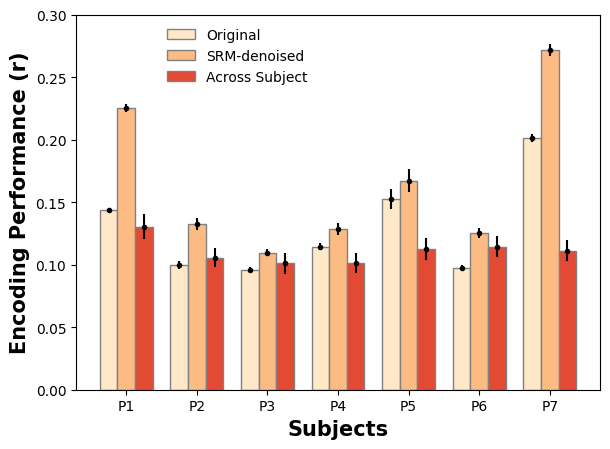

Brainplot: Original_encoding
Coordinate matrix shape:  (168, 3)
Brainplot: eSRM-denoised Encoding
Coordinate matrix shape:  (168, 3)
Brainplot: Across Subject Encoding
Coordinate matrix shape:  (168, 3)
Brainplot: eSRM-denoised Encoding - Original_encoding 
Coordinate matrix shape:  (168, 3)


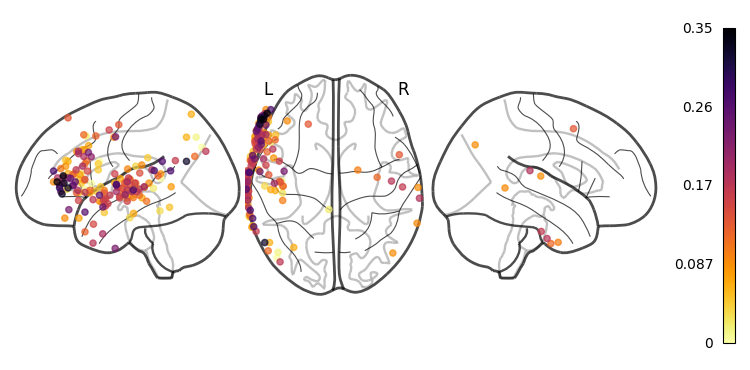

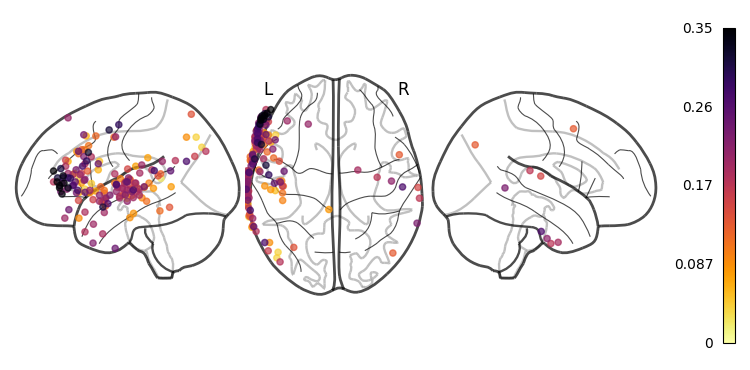

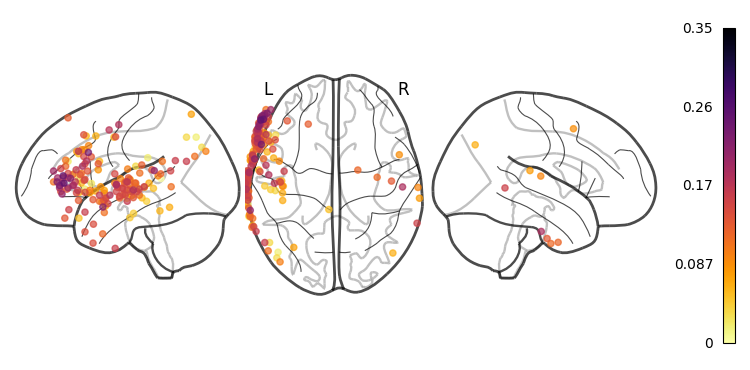

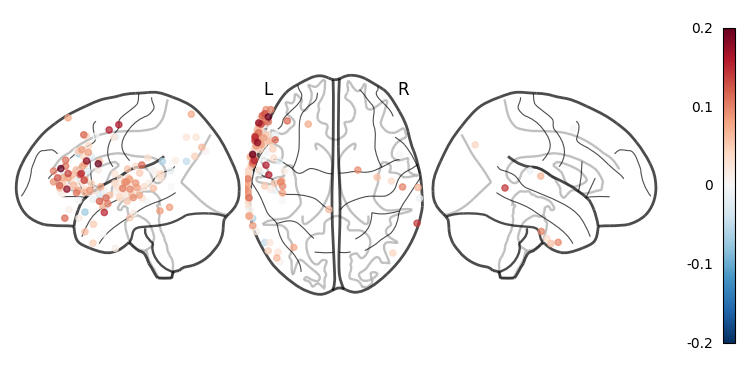

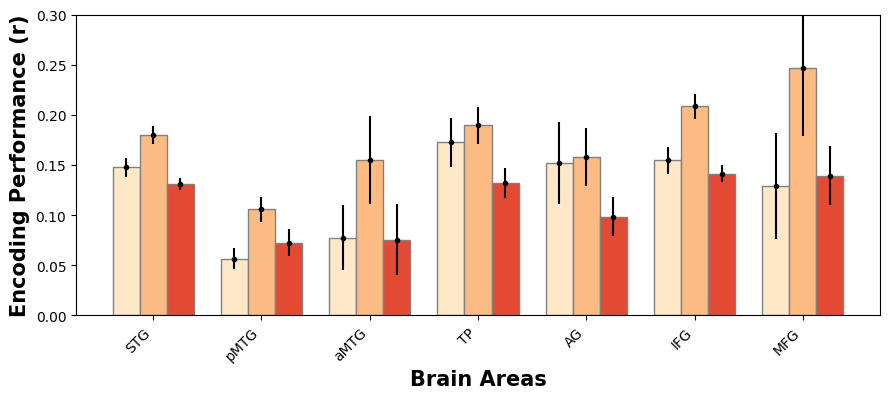

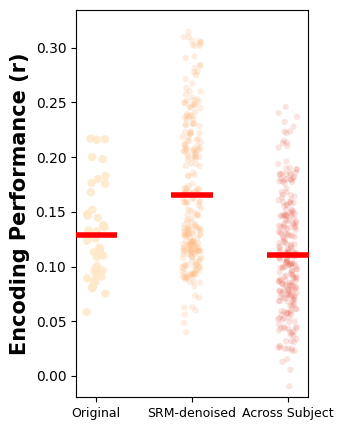

In [70]:
# ============================================================
# Initialize containers for performance metrics and bookkeeping
# ============================================================

subject1=[]
subject2=[]
fold=[]
all_perm=[]
all_index=[]
srm_denoised=[]
original_encoding=[]
srm_across_subject=[]
reconstruction_across_subject=[]
reconstruction_control_isc=[]
shared_space_encoding=[]
index=[]

index_srm=[]
index_analysis=[]

srm_features=args.srm_k
srm_k=args.srm_k


# ============================================================
# Generate all possible train/test fold permutations.
#
# Each fold uses a different ordering of the three story
# segments:
#   segment 1 -> alignment/training
#   segment 2 -> alignment/training
#   segment 3 -> evaluation
# ============================================================

perm1= permutations(np.arange(0,3), 3) 

for i in perm1: 
    all_index.append(i)

# ============================================================
# Generate all ordered subject pairs.
#
# Example:
#   (S1,S2) is treated differently from (S2,S1)
# because encoding and transfer are directional.
# ============================================================

perm= permutations(np.arange(0,len(subjects)), 2) 

for i in perm: 
    all_perm.append(i)

# ============================================================
# Define segment boundaries used for SRM alignment.
#
# Story is split into three contiguous parts.
# Boundaries differ because GPT-2 and GloVe have
# different numbers of aligned words.
# ============================================================

# if args.embedding_for_alignment=='gpt2xl':
        
#     index1=np.arange(0,1712)      #1671 for gpt2 #1407 for glove
#     index2=np.arange(1712,3424)   #3342 for gpt2 #2814 glove 
#     index3=np.arange(3424,5136)   #5013 for gpt2 #4221 for glove 

#     index_srm.append(index1)
#     index_srm.append(index2)
#     index_srm.append(index3)


# if args.embedding_for_alignment=='glove':

## index for alignment (the story is divided in 3 equal segments)

index1=np.arange(0,int(word_embeddings_srm.shape[0]/3)) 
index2=np.arange(int(word_embeddings_srm.shape[0]/3),2*int(word_embeddings_srm.shape[0]/3)) 
index3=np.arange(2*int(word_embeddings_srm.shape[0]/3), word_embeddings_srm.shape[0]) 

index_srm.append(index1)
index_srm.append(index2)
index_srm.append(index3)

# ============================================================
# Define segment boundaries used for downstream analyses.
# Alignment and downstream embeddings may differ.
# ============================================================

# if args.embedding_for_downstream_analysis=='gpt2xl':
        
#     index1=np.arange(0,1712)      #1671 for gpt2 #1407 for glove
#     index2=np.arange(1712,3424)   #3342 for gpt2 #2814 glove 
#     index3=np.arange(3424,5136)   #5013 for gpt2 #4221 for glove 

#     index_analysis.append(index1)
#     index_analysis.append(index2)
#     index_analysis.append(index3)


# if args.embedding_for_downstream_analysis=='glove':

# story segmentation for downstream evaluation
index1=np.arange(0,int(word_embeddings_analysis.shape[0]/3)) 
index2=np.arange(int(word_embeddings_analysis.shape[0]/3),2*int(word_embeddings_analysis.shape[0]/3)) 
index3=np.arange(2*int(word_embeddings_analysis.shape[0]/3), word_embeddings_analysis.shape[0]) 

index_analysis.append(index1)
index_analysis.append(index2)
index_analysis.append(index3)

# ============================================================
# Create electrode-level dataframes that will store
# performance values for each analysis.
# ============================================================

df_all_data_org_encoding=make_df(df_all_sub)
df_all_data_srm_denoise=make_df(df_all_sub)
df_all_data_across_subject=make_df(df_all_sub)


# ============================================================
# Main analysis loop:
#
# For each ordered subject pair:
#   1. Build SRM alignment using neural encoding weights.
#   2. Evaluate within-subject encoding.
#   3. Evaluate SRM-denoised encoding.
#   4. Evaluate transfer across subjects.
#   5. Evaluate encoding directly in shared space.
# ============================================================

# %%%%%%%%%%%%%%%%%%%%%%%%%
step_count=0
step_count2=0
starting=0
ignore=0
for sub_index in range(len(all_perm)):

    if sub_index%10==0:
        print(sub_index)
    sub1=all_perm[sub_index][0]
    sub2=all_perm[sub_index][1]

    if starting==0:
        pre_sub1=sub1.copy()
        pre_sub2=sub2.copy()
        starting=1
        

    if pre_sub1!=sub1:
        pre_sub1=sub1.copy()
        step_count=0
        ignore=step_count2
        # step_count2=step_count2+1
        starting2=0
        

    if pre_sub2!=sub2:
        pre_sub2=sub2.copy()
        # if starting2=0:
        step_count2=ignore
    
    p=0

    # ========================================================
    # Iterate over all train/test fold assignments.
    # ========================================================
    
    for index_id in all_index:
        
        step_count=step_count+1
        step_count2=step_count2+1
        
        # print('fold:',p)
        fold.append(p+1)
        subject1.append(subjects[sub1])
        subject2.append(subjects[sub2])

        # ----------------------------------------------------
        # Split embeddings into three story segments.
        # ----------------------------------------------------
        
        emb1_srm=word_embeddings_srm[index_srm[index_id[0]],:]
        emb2_srm=word_embeddings_srm[index_srm[index_id[1]],:]
        emb3_srm=word_embeddings_srm[index_srm[index_id[2]],:]

        emb1_analysis=word_embeddings_analysis[index_analysis[index_id[0]],:]
        emb2_analysis=word_embeddings_analysis[index_analysis[index_id[1]],:]
        emb3_analysis=word_embeddings_analysis[index_analysis[index_id[2]],:]

        # ----------------------------------------------------
        # Extract the corresponding neural responses
        # for each subject and segment.
        # ----------------------------------------------------        
        
        sub1_part1_srm=Y_data_srm[sub1,0,index_srm[index_id[0]],:elec_num[sub1]]
        sub1_part2_srm=Y_data_srm[sub1,0,index_srm[index_id[1]],:elec_num[sub1]]
        sub1_part3_srm=Y_data_srm[sub1,0,index_srm[index_id[2]],:elec_num[sub1]]
        
        sub2_part1_srm=Y_data_srm[sub2,0,index_srm[index_id[0]],:elec_num[sub2]]
        sub2_part2_srm=Y_data_srm[sub2,0,index_srm[index_id[1]],:elec_num[sub2]]
        sub2_part3_srm=Y_data_srm[sub2,0,index_srm[index_id[2]],:elec_num[sub2]]

        sub1_part1_analysis=Y_data_analysis[sub1,0,index_analysis[index_id[0]],:elec_num[sub1]]
        sub1_part2_analysis=Y_data_analysis[sub1,0,index_analysis[index_id[1]],:elec_num[sub1]]
        sub1_part3_analysis=Y_data_analysis[sub1,0,index_analysis[index_id[2]],:elec_num[sub1]]
        
        sub2_part1_analysis=Y_data_analysis[sub2,0,index_analysis[index_id[0]],:elec_num[sub2]]
        sub2_part2_analysis=Y_data_analysis[sub2,0,index_analysis[index_id[1]],:elec_num[sub2]]
        sub2_part3_analysis=Y_data_analysis[sub2,0,index_analysis[index_id[2]],:elec_num[sub2]]

        # ====================================================
        # SRM ALIGNMENT
        #
        # First estimate encoding weights from embeddings
        # to neural responses for each subject. Those
        # encoding weights are then aligned using SRM.
        # ====================================================

        #for alignment
        reg1 = LinearRegression().fit(emb1_srm,sub1_part1_srm)
        reg2 = LinearRegression().fit(emb2_srm,sub2_part2_srm)
        
        theta1=(reg1.coef_)
        theta2=(reg2.coef_)
        
        train_data=[]
        
        train_data.append(theta1)
        train_data.append(theta2)
        
        srm = brainiak.funcalign.srm.SRM(n_iter=100, features=srm_features)
        srm.fit(train_data)

        # ====================================================
        # WITHIN-SUBJECT ENCODING
        #
        # Compare standard encoding against encoding after
        # projection through an SRM-derived denoising space.
        # ====================================================
        
        
        # k=0
        w0 = srm.w_[0]  # Weights for subject 0
        
        Y_train_srm=np.matmul(np.matmul(sub1_part1_analysis,w0),w0.T)
        Y_test_srm=np.matmul(np.matmul(sub1_part3_analysis,w0),w0.T)
        
        Y_train=sub1_part1_analysis
        Y_test=sub1_part3_analysis
        
        reg3 = LinearRegression().fit(emb1_analysis,Y_train_srm)
        reg4 = LinearRegression().fit(emb1_analysis,Y_train)
        
        Y_pred_srm=reg3.predict(emb3_analysis)
        Y_pred=reg4.predict(emb3_analysis)
        
        a1=[]
        a2=[]
        for elec in range(np.shape(Y_pred)[1]):
            
            a1.append(np.corrcoef(Y_test_srm[:,elec],Y_pred_srm[:,elec])[0,1])
            a2.append(np.corrcoef(Y_test[:,elec],Y_pred[:,elec])[0,1])
        
        srm_denoised.append(np.mean(a1))
        original_encoding.append(np.mean(a2))


        ## adding data to csv for all elec
        df_all_data_srm_denoise=add_data_to_df(df_all_data_srm_denoise,step_count,sub1,a1)
        df_all_data_org_encoding=add_data_to_df(df_all_data_org_encoding,step_count,sub1,a2)

        # ====================================================
        # ACROSS-SUBJECT TRANSFER
        #
        # Use subject 1 model predictions and project them
        # into subject 2's SRM space for evaluation.
        # ====================================================
        
        #across subject encoding            
        w0 = srm.w_[0]  # Weights for subject 0
        w1 = srm.w_[1]  # Weights for subject 1
        
        # Y_test_srm_across=np.matmul(np.matmul(sub2_part3,w1),w0.T)

        Y_test_srm_across=np.matmul(np.matmul(sub2_part3_analysis,w1),w1.T)
        # Y_test_srm_across=sub2_part3
        Y_pred_srm2=np.matmul(np.matmul(Y_pred_srm,w0),w1.T)
        
        a3=[]
        a4=[] 

        for elec in range(np.shape(Y_pred_srm2)[1]):
            
            a3.append(np.corrcoef(Y_test_srm_across[:,elec],Y_pred_srm2[:,elec])[0,1])
            # a4.append(np.corrcoef(Y_test_srm_across[:,elec],Y_test_srm[:,elec])[0,1])


        srm_across_subject.append(np.mean(a3))
        df_all_data_across_subject=add_data_to_df(df_all_data_across_subject,step_count2,sub2,a3)
        

        # ====================================================
        # SHARED-SPACE ENCODING
        #
        # Train and evaluate solely within the SRM common
        # space rather than individual electrode space.
        # ====================================================

        
        Y_train_srm=np.matmul(sub1_part1_analysis,w0)
        Y_test_srm=np.matmul(sub1_part3_analysis,w0)

        reg6 = LinearRegression().fit(emb1_analysis,Y_train_srm)
        Y_pred_srm=reg6.predict(emb3_analysis)
        
        
        a6=[]
        
        for elec in range(srm_features):
            
            a6.append(np.corrcoef(Y_test_srm[:,elec],Y_pred_srm[:,elec])[0,1])
            
        
        shared_space_encoding.append(np.mean(a6))
        
        p=p+1

# ============================================================
# Save summary results for each fold and subject pair.
# ============================================================

df_srm=pd.DataFrame()
df_srm['fold']=fold
df_srm['subject1']=subject1
df_srm['subject2']=subject2
df_srm['within_sub_encoding_sub1']=original_encoding
df_srm['srm_denoised_sub1']=srm_denoised
df_srm['across_subject_sub1']=srm_across_subject
# df_srm['reconstruction_across_subject_sub1']=reconstruction_across_subject
# df_srm['reconstruction_control_isc']=reconstruction_control_isc
df_srm['shared_space_encoding']=shared_space_encoding

# path='/scratch/gpfs/arnab/Encoding/result/sam_work'
# path='/scratch/gpfs/HASSON/arnab/model_based_srm/result/podcast/'
path=os.getcwd()

# os.chdir(path)
# df_srm.to_csv('csrm_ecog_gpt2_erp_corr_elec_threshold_25.csv', index=False)


# Create a timestamped results directory so each run
# is stored independently.
timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

# Define folder name
folder_name = f"{path}/results/podcast_data/all_data_elec_{args.elec}_srm_{srm_k}_{timestamp}"
filename=folder_name+'/csrm_ecog_gpt2_'+ args.elec+'.csv'
# Create the folder
os.makedirs(folder_name)


# Save aggregate and electrode-level results.
df_srm.to_csv(filename, index=False)
df_all_data_org_encoding.to_csv(f"{folder_name}/all_data_ecog_gpt2_{args.elec}_org_encoding.csv", index=False)
df_all_data_srm_denoise.to_csv(f"{folder_name}/all_data_ecog_gpt2_{args.elec}_srm_denoise.csv", index=False)
df_all_data_across_subject.to_csv(f"{folder_name}/all_data_ecog_gpt2_{args.elec}_across_subject.csv", index=False)

# Generate figures and save run configuration.
make_result_bar_plot(args, folder_name,df_srm, )
make_all_plots(args, folder_name,df_all_sub)
areas=['STG','pmtg', 'aMTG', 'TP', 'AG','IFG','MFG']
make_area_bar_plot(args, folder_name, areas=areas)
point_plot(args, folder_name, df_srm)
save_args_to_file(folder_name,args)

In [59]:
# significance test between original encoding and eSRM denoised encoding for each subject

threshold = 0.01
subject_wise_significance=[]

for sub in subjects:
    org=df_srm[df_srm.subject1==sub].within_sub_encoding_sub1
    srm=df_srm[df_srm.subject1==sub].srm_denoised_sub1
    
    r = ttest_rel(org,srm,alternative="two-sided") #ttest_rel

    rs = fdr(r[1])
    
    if rs<threshold:
        subject_wise_significance.append(f'subject-{sub}: significant')
    else:
        subject_wise_significance.append(f'subject-{sub}: not significant')

subject_wise_significance

['subject-3: significant',
 'subject-4: significant',
 'subject-5: significant',
 'subject-6: significant',
 'subject-7: significant',
 'subject-8: significant',
 'subject-9: significant']